# Lecture 4: Hilbert Space and the Postulates of Quantum Mechanics I

[Course contents](../00_course_contents.md) | [← Previous lecture](./03_complex_numbers_and_operators.ipynb) | [Next lecture →](./05_quantum_dynamics_and_measurement.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** This notebook may be downloaded, taught, adapted, and shared with attribution. It supports institutional teaching, independent study, examination review, and preparation for quantum-technology roles. See the [reuse terms](../LICENSE), [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and [citation metadata](../CITATION.cff).

## Learning objectives

- Explain completeness, orthonormal expansions, and the role of a basis in a Hilbert space.
- Distinguish normalized vectors, physical rays, projectors, and measurement probabilities.
- Represent a qubit in several orthonormal bases and preview composite-system state spaces.

## Core ideas

- **A Hilbert space is complete.** Convergent sequences of physical approximations must have limits inside the space.
- **A pure state is a ray, not a unique vector.** Vectors that differ only by global phase represent the same state.
- **Measurement probabilities depend on the chosen measurement basis, not on a passive relabeling of coordinates.**


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
from sympy.plotting import plot
from sympy.physics.quantum.qubit import Qubit
from sympy.physics.quantum.dagger import Dagger
from sympy.physics.quantum.represent import represent
from sympy.physics.quantum.qapply import qapply
import numpy as np
import matplotlib.pyplot as plt
import sympy as sy
from IPython.display import display

In [2]:
%matplotlib inline

A **Hilbert space** is a real or complex inner-product space that is complete in the norm induced by its inner product. Completeness means that every Cauchy sequence converges to a vector that remains inside the space. Hilbert spaces may be finite- or infinite-dimensional. A qubit uses $\mathbb C^2$; square-integrable wavefunctions form an important infinite-dimensional example.

Pure quantum states are represented by normalized vectors up to a common global phase, equivalently by rays. Observables are represented by self-adjoint operators, with domain qualifications required in infinite-dimensional spaces.


## Square-integrable functions as vectors


For complex-valued functions on an interval $[a,b]$, define

$$
\langle f|g\rangle=\int_a^b f^*(x)g(x)\,dx.
$$

The functions are orthogonal when $\langle f|g\rangle=0$. A function belongs to $L^2([a,b])$ when $\int_a^b|f(x)|^2\,dx<\infty$. Strictly speaking, $L^2$ vectors are equivalence classes of functions that differ only on sets of measure zero.


For integers $n,m\geq1$, the functions

$$
f_n(x)=\frac{1}{\sqrt\pi}\cos(nx),\qquad
g_n(x)=\frac{1}{\sqrt\pi}\sin(nx)
$$

are normalized on $[-\pi,\pi]$. The cosine and sine families are mutually orthogonal, and $\langle f_n|f_m\rangle=\langle g_n|g_m\rangle=\delta_{nm}$. A complete Fourier basis also includes the constant function $1/\sqrt{2\pi}$.


In [3]:
x = sy.symbols('x', real=True)
f3 = sy.cos(3 * x) / sy.sqrt(sy.pi)
g1 = sy.sin(x) / sy.sqrt(sy.pi)

function_plot = plot(f3, g1, (x, -sy.pi, sy.pi), size=(5, 3), show=False)
product_plot = plot(f3 * g1, (x, -sy.pi, sy.pi), size=(5, 3), show=False)
display(function_plot, product_plot)

In [4]:
inner_f3_g1 = sy.integrate(sy.conjugate(f3) * g1, (x, -sy.pi, sy.pi))
display(inner_f3_g1)

0

In [5]:
norm_plot = plot(f3 * f3, (x, -sy.pi, sy.pi), size=(5, 3), show=False)
norm_f3 = sy.integrate(sy.conjugate(f3) * f3, (x, -sy.pi, sy.pi))
display(norm_plot, norm_f3)

1

In [6]:
f2 = sy.cos(2 * x) / sy.sqrt(sy.pi)
orthogonality_plot = plot(f2 * f3, (x, -sy.pi, sy.pi), size=(5, 3), show=False)
inner_f2_f3 = sy.integrate(sy.conjugate(f2) * f3, (x, -sy.pi, sy.pi))
display(orthogonality_plot, inner_f2_f3)

0

## Completeness, Parseval's identity, and truncation error

For a complete orthonormal basis $\{u_n\}$,

$$
|f\rangle=\sum_n c_n|u_n\rangle,
\qquad c_n=\langle u_n|f\rangle,
$$

with convergence in the Hilbert-space norm. Parseval's identity states

$$
\|f\|^2=\sum_n|c_n|^2.
$$

If only the first $N$ terms are retained, the squared norm of the omitted component is $\sum_{n>N}|c_n|^2$. This provides a quantitative truncation error for basis-based simulations.


In [7]:
# Parseval check for a normalized vector in a random orthonormal basis
rng = np.random.default_rng(4)
trial = rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4))
Q, _ = np.linalg.qr(trial)
f = np.array([1, 1j, 2, -1j], dtype=complex)
f /= np.linalg.norm(f)
coefficients = Q.conj().T @ f

print("vector norm squared:", np.vdot(f, f).real)
print("coefficient norm squared:", np.vdot(coefficients, coefficients).real)

vector norm squared: 0.9999999999999998
coefficient norm squared: 1.0


### Fourier expansion in an orthonormal function basis

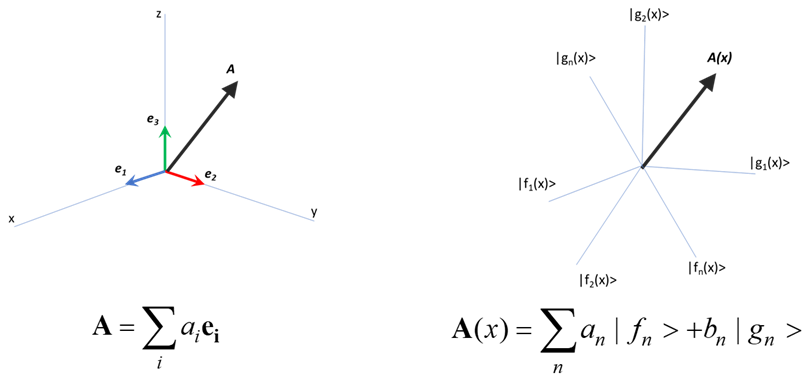

*The coordinate-space sketch is a finite-dimensional analogy: vector components resolve an arrow in a basis just as Fourier coefficients resolve a function in orthonormal modes.*


For the orthonormal Fourier basis, let $u_0(x)=1/\sqrt{2\pi}$ and write

$$
A(x)=a_0u_0(x)
+\sum_{n=1}^{\infty}\left[a_nf_n(x)+b_ng_n(x)\right].
$$

Taking an inner product isolates one coefficient:

$$
\begin{aligned}
\langle f_m|A\rangle
&=a_0\langle f_m|u_0\rangle\\
&\quad+\sum_{n=1}^{\infty}
\left[a_n\langle f_m|f_n\rangle
+b_n\langle f_m|g_n\rangle\right]
=a_m.
\end{aligned}
$$

Thus $a_n=\langle f_n|A\rangle$, $b_n=\langle g_n|A\rangle$, and $a_0=\langle u_0|A\rangle$.


Complex functions can therefore be treated as vectors. In an infinite-dimensional Hilbert space, convergence is defined by the norm, not necessarily by pointwise convergence at every coordinate.


## Eigenmode decompositions

For a self-adjoint eigenvalue problem with suitable boundary conditions, discrete eigenfunctions belonging to distinct eigenvalues are orthogonal and may form a basis. A vibrating string is a standard example. More general systems can have degeneracies, continuous spectra, or both, so a discrete sum of eigenmodes is not universally sufficient.

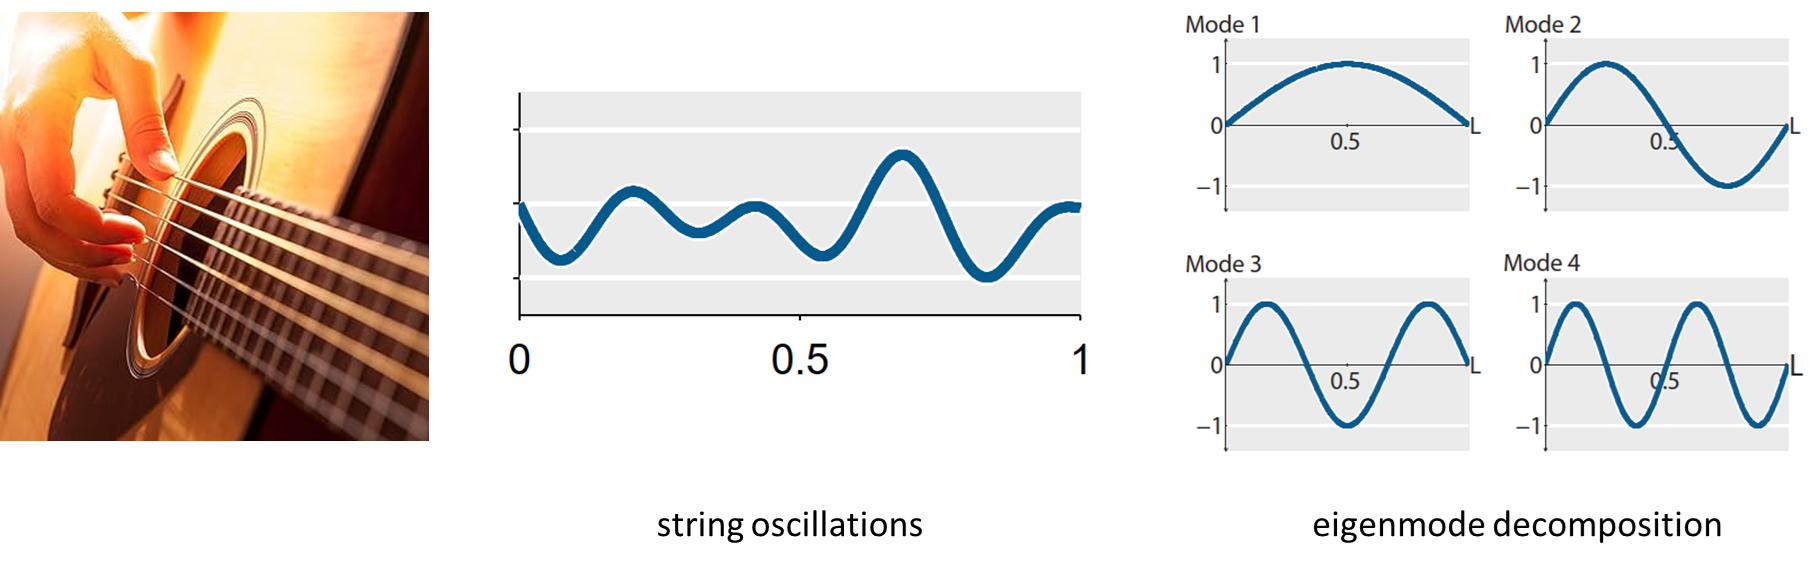

*The composite string displacement is shown beside several sinusoidal normal modes whose weighted sum can reconstruct it.*


Mode decompositions organize many wave problems—from macroscopic resonators to nanostructures—when the relevant linear operator and boundary conditions admit such modes.

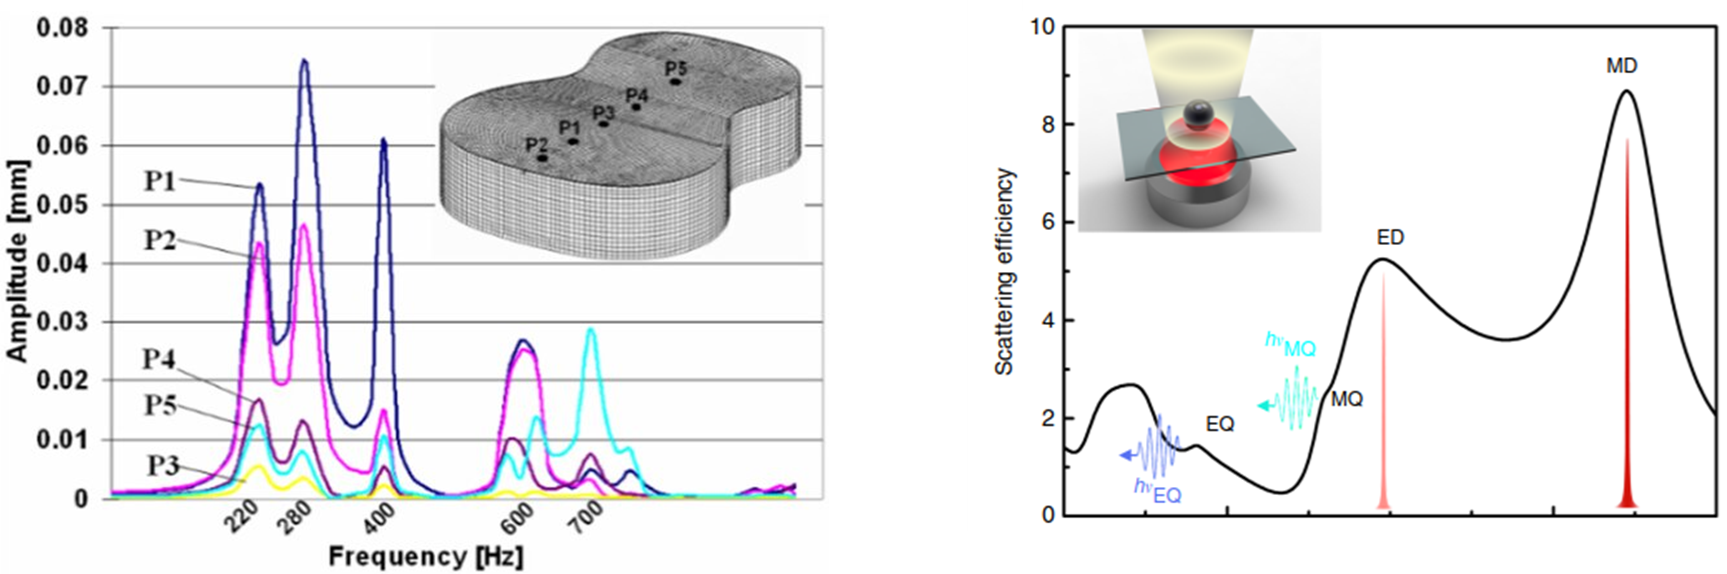

*The plots pair resonance peaks with labeled spatial modes, illustrating how experimental response can be decomposed into eigenmodes.*


## Orthonormal bases in Hilbert space

For a complete orthonormal basis $\{|u_n\rangle\}$, a vector has the norm-convergent expansion

$$
|\psi\rangle=\sum_n c_n|u_n\rangle,
\qquad c_n=\langle u_n|\psi\rangle.
$$

Two orthonormal coordinate bases are related by a unitary transformation. For a nonorthonormal basis, coefficients are not obtained by simple projections and the basis change is generally invertible but not unitary.


## Rays and the distinction between global and relative phase

Normalization selects unit vectors, but it does not choose a unique representative of a physical pure state: $|\psi\rangle$ and $e^{i\gamma}|\psi\rangle$, with $\gamma\in\mathbb R$, define the same ray. For every projector $P$,

$$
\langle e^{i\gamma}\psi|P|e^{i\gamma}\psi\rangle
=\langle\psi|P|\psi\rangle.
$$

By contrast, changing only one component changes a relative phase and can affect interference. Thus $(|0\rangle+|1\rangle)/\sqrt2$ and $(|0\rangle-|1\rangle)/\sqrt2$ are distinct orthogonal states.


In [8]:
state = np.array([1, 1j], dtype=complex) / np.sqrt(2)
phase_shifted = np.exp(1j * 0.73) * state
relative_phase_changed = np.array([1, -1j], dtype=complex) / np.sqrt(2)

print("global-phase overlap magnitude:", abs(np.vdot(state, phase_shifted)))
print("relative-phase overlap magnitude:", abs(np.vdot(state, relative_phase_changed)))

global-phase overlap magnitude: 0.9999999999999999
relative-phase overlap magnitude: 0.0


## The two-dimensional Hilbert space of a qubit

A qubit is a quantum system whose state space is two-dimensional. It has infinitely many pure states, although every orthonormal measurement basis contains two basis vectors. In coordinates,

$$
|a\rangle=\begin{bmatrix}a_0\\a_1\end{bmatrix},
\qquad \langle a|=\begin{bmatrix}a_0^*&a_1^*\end{bmatrix}.
$$

The inner product is $\langle b|a\rangle=b_0^*a_0+b_1^*a_1$, and the outer product $|a\rangle\langle b|$ is a $2\times2$ operator.


The computational basis is

$$
|0\rangle=\begin{bmatrix}1\\0\end{bmatrix},\qquad
|1\rangle=\begin{bmatrix}0\\1\end{bmatrix}.
$$


SymPy's `Qubit` class constructs computational-basis kets. `Qubit(0)` and `Qubit(1)` are one-qubit basis states; superpositions are ordinary symbolic linear combinations of these kets.


In [9]:
zero = Qubit(0)
one = Qubit(1)
display(zero, one)

|0>

|1>

In [10]:
display(Dagger(zero), Dagger(zero) * one)

<0|

<0|1>

In [11]:
display((Dagger(zero) * one).doit(), (Dagger(zero) * zero).doit())

0

1

In [12]:
display((zero * Dagger(one)).doit())

|0><1|

In [13]:
display(represent(zero), represent(one))

Matrix([
[1],
[0]])

Matrix([
[0],
[1]])

In [14]:
display(
    represent(zero * Dagger(zero)),
    represent(zero * Dagger(one)),
    represent(one * Dagger(zero)),
    represent(one * Dagger(one)),
)

Matrix([
[1, 0],
[0, 0]])

Matrix([
[0, 1],
[0, 0]])

Matrix([
[0, 0],
[1, 0]])

Matrix([
[0, 0],
[0, 1]])

The four outer products $|i\rangle\langle j|$, for $i,j\in\{0,1\}$, form a basis for all $2\times2$ complex matrices:

$$
\begin{bmatrix}a&b\\c&d\end{bmatrix}
=a|0\rangle\langle0|+b|0\rangle\langle1|
+c|1\rangle\langle0|+d|1\rangle\langle1|.
$$

The computational basis also resolves the identity,

$$
|0\rangle\langle0|+|1\rangle\langle1|=I.
$$

More generally, $\sum_n|u_n\rangle\langle u_n|=I$ for a complete orthonormal basis.


## Projectors and measurement geometry

For a normalized vector $|u\rangle$,

$$
P_u=|u\rangle\langle u|
$$

projects onto its one-dimensional span. For a normalized state $|\psi\rangle$, the Born probability associated with that projector is

$$
p(u)=\langle\psi|P_u|\psi\rangle
=|\langle u|\psi\rangle|^2.
$$

A projective measurement is described by mutually orthogonal projectors $P_k$ satisfying $P_jP_k=\delta_{jk}P_k$ and $\sum_kP_k=I$. Rank-one projectors are a special case; degenerate outcomes correspond to higher-rank subspaces.


In [15]:
psi_numeric = np.array([1, 1j], dtype=complex) / np.sqrt(2)
zero_numeric = np.array([1, 0], dtype=complex)
P0 = np.outer(zero_numeric, zero_numeric.conj())

probability_zero = np.vdot(psi_numeric, P0 @ psi_numeric).real
print("P(0):", probability_zero)
print("projector idempotent:", np.allclose(P0 @ P0, P0))

P(0): 0.4999999999999999
projector idempotent: True


A qubit state may be a coherent superposition

$$
|\psi\rangle=\alpha|0\rangle+\beta|1\rangle,
\qquad |\alpha|^2+|\beta|^2=1.
$$

The unnormalized vector $|0\rangle+|1\rangle$ has squared norm $2$.


In [16]:
Dagger(Qubit(0) + Qubit(1))*(Qubit(0)+Qubit(1))

(<0| + <1|)*(|0> + |1>)

In [17]:
qapply(Dagger(Qubit(0) + Qubit(1))*(Qubit(0)+Qubit(1)))

2

The corresponding normalized state is $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$.


The orthogonal state

$$
|-\rangle=\frac{|0\rangle-|1\rangle}{\sqrt2}
$$

is obtained from $|+\rangle$ by changing the relative phase of the $|1\rangle$ coefficient by $\pi$. Calling one state “constructive” and the other “destructive” is meaningful only after specifying a transformation and measurement basis; for example, a Hadamard sends them to different computational-basis states.


These states are also orthonormal:


In [18]:
ps = 1/sy.sqrt(2)*(Qubit(0)+Qubit(1))
ms = 1/sy.sqrt(2)*(Qubit(0)-Qubit(1))

In [19]:
display(ps, ms)

sqrt(2)*(|0> + |1>)/2

sqrt(2)*(|0> - |1>)/2

In [20]:
display(
    qapply(Dagger(ps) * ps),
    qapply(Dagger(ms) * ms),
    qapply(Dagger(ps) * ms),
)

1

1

0

Because $|+\rangle$ and $|-\rangle$ are orthonormal, they form a basis. The computational-basis states have the expansions

$$
|0\rangle=\frac{|+\rangle+|-\rangle}{\sqrt2},\qquad
|1\rangle=\frac{|+\rangle-|-\rangle}{\sqrt2}.
$$


In [21]:
display(qapply((ps + ms) / sy.sqrt(2)), qapply((ps - ms) / sy.sqrt(2)))

|0>

|1>

A third frequently used basis is the Pauli-$Y$ eigenbasis:

$$
|+i\rangle=\frac{|0\rangle+i|1\rangle}{\sqrt2},\qquad
|-i\rangle=\frac{|0\rangle-i|1\rangle}{\sqrt2}.
$$


In [22]:
plus_i = (Qubit(0) + sy.I * Qubit(1)) / sy.sqrt(2)
minus_i = (Qubit(0) - sy.I * Qubit(1)) / sy.sqrt(2)

display(
    qapply(Dagger(plus_i) * plus_i),
    qapply(Dagger(minus_i) * minus_i),
    qapply(Dagger(plus_i) * minus_i),
)

1

1

0

## Three standard qubit bases

The computational, $X$, and $Y$ bases are

$$
\{|0\rangle,|1\rangle\},\qquad
\{|+\rangle,|-\rangle\},\qquad
\{|+i\rangle,|-i\rangle\}.
$$

They are the eigenbases of the Pauli matrices $Z$, $X$, and $Y$, respectively. A passive coordinate change re-expresses both states and operators and leaves every physical probability unchanged. Choosing to measure in the $X$, $Y$, or $Z$ eigenbasis is instead a different physical measurement and can produce a different outcome distribution.


In [23]:
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

plus_numeric = np.array([1, 1], dtype=complex) / np.sqrt(2)
plus_i_numeric = np.array([1, 1j], dtype=complex) / np.sqrt(2)

print("X|+> = |+>:", np.allclose(X @ plus_numeric, plus_numeric))
print("Y|+i> = |+i>:", np.allclose(Y @ plus_i_numeric, plus_i_numeric))
print("Z|0> = |0>:", np.allclose(Z @ zero_numeric, zero_numeric))

X|+> = |+>: True
Y|+i> = |+i>: True
Z|0> = |0>: True


## Quantum-mechanical state and measurement principles

The postulates of quantum mechanics can be grouped in several equivalent ways. The following statements introduce the state space, Born rule, and observables; dynamics and general measurements are developed in later lectures.


## State principle

A pure state is represented by a normalized vector in a complex Hilbert space, with vectors that differ only by a common global phase representing the same physical state:

$$
|\psi\rangle\sim e^{i\gamma}|\psi\rangle,
\qquad \gamma\in\mathbb R.
$$


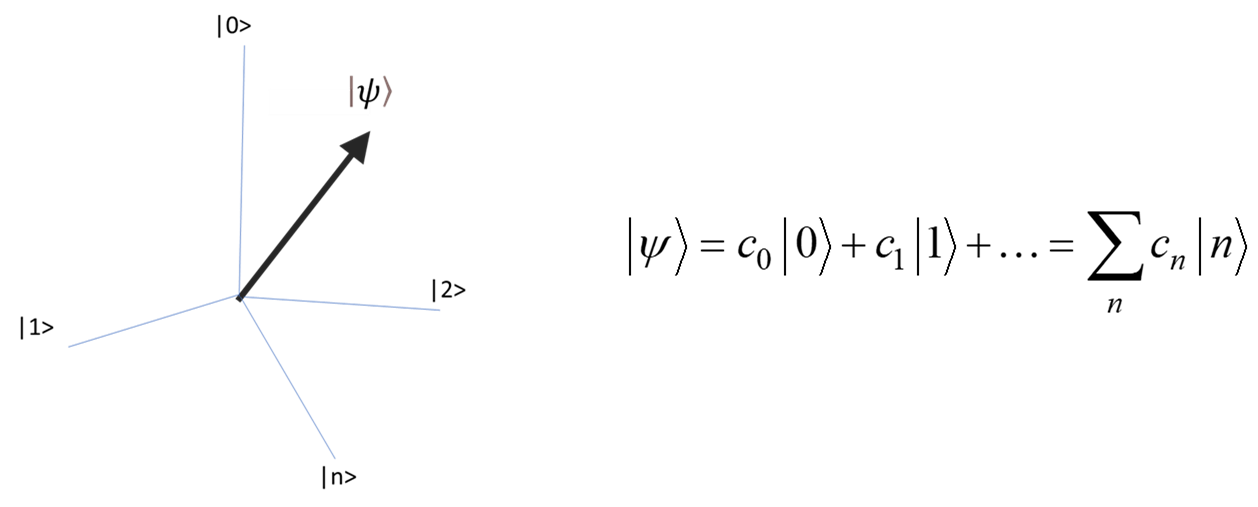

*The ket is drawn as an arrow to emphasize that a state vector acquires coordinates only after a basis is selected.*


> **Example 1: a particle with a spatial degree of freedom.** A wavefunction describes its spatial pure state. A slit changes the transmitted spatial state, and later position-detection probabilities follow from the Born rule.

> 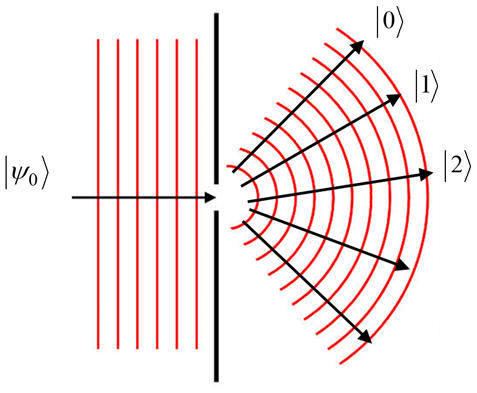

*The aperture changes the transmitted spatial state, and the curved outgoing wavefronts indicate diffraction rather than a classical point trajectory.*


> **Example 2: a two-level system.** Two selected orthogonal levels span a qubit Hilbert space, provided leakage to other levels can be neglected.

> 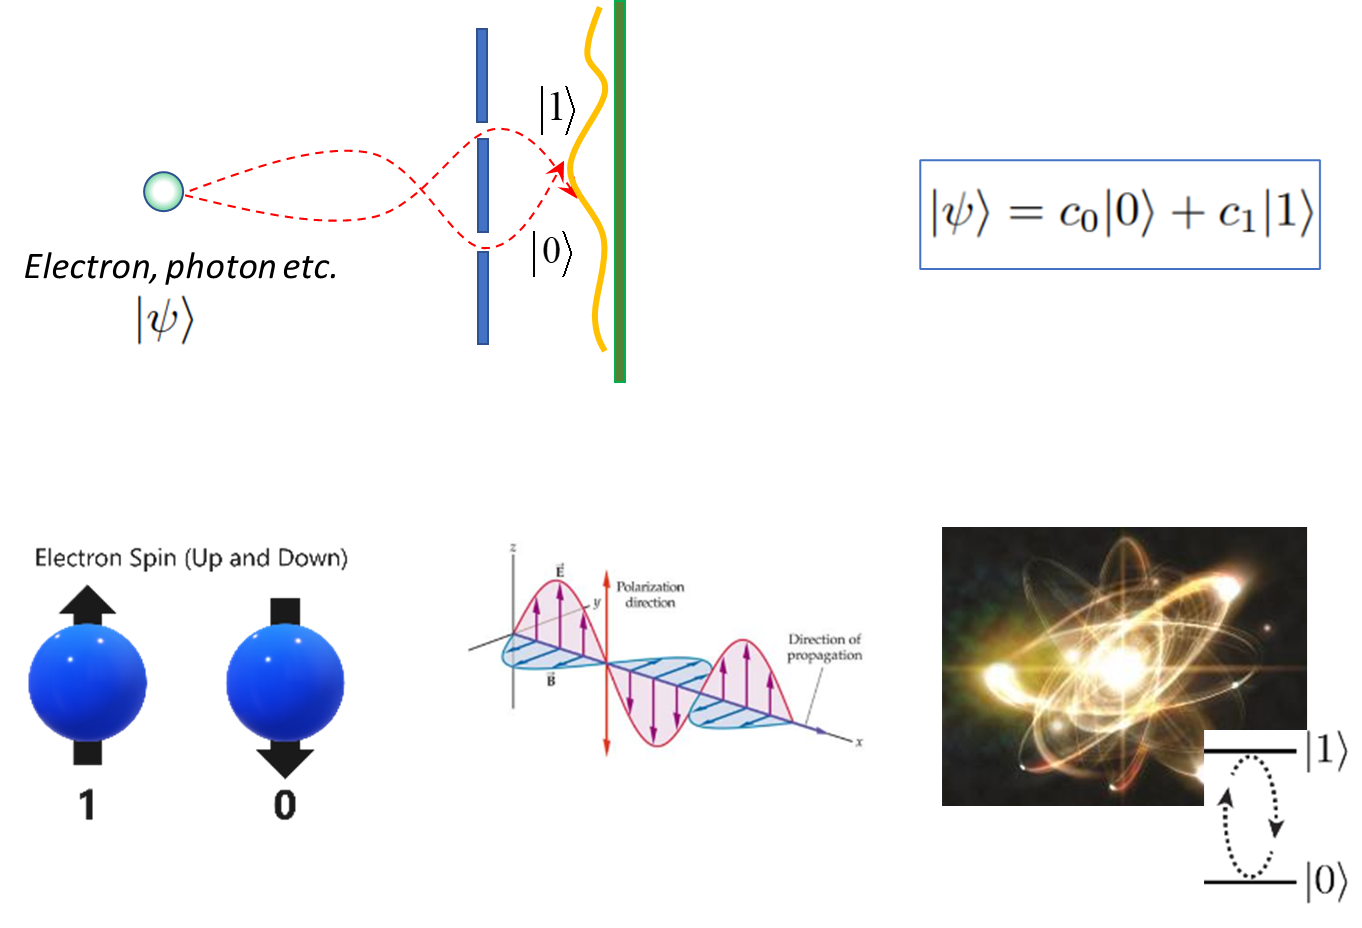

*The montage contrasts several physical degrees of freedom that can carry quantum states; the common two-level notation does not imply identical hardware.*


## Born rule

For a normalized state $|\psi\rangle$ and an orthonormal measurement basis $\{|n\rangle\}$, the probability of outcome $n$ is

$$
p(n)=|\langle n|\psi\rangle|^2.
$$

The coefficients $c_n=\langle n|\psi\rangle$ are probability amplitudes in that basis, and completeness guarantees $\sum_n p(n)=1$.


In [24]:
c0, c1 = sy.symbols('c_0, c_1', complex=True)

In [25]:
psi = c0*Qubit(0)+c1*Qubit(1)
psi

c_0*|0> + c_1*|1>

In [26]:
amplitude_zero = qapply(Dagger(Qubit(0)) * psi)
display(Dagger(Qubit(0)) * psi, amplitude_zero)

<0|*(c_0*|0> + c_1*|1>)

c_0

For a normalized qubit state $c_0|0\rangle+c_1|1\rangle$, computational-basis probabilities are $|c_0|^2$ and $|c_1|^2$, and their sum is one.


## Observable principle

In finite dimensions, a physical observable is represented by a Hermitian operator $\hat O^\dagger=\hat O$. In infinite dimensions, the appropriate condition is self-adjointness together with the operator's domain. The Hamiltonian $\hat H$ is the observable associated with energy.


For a finite-dimensional ideal projective measurement of $O$, the possible outcomes are its real eigenvalues. The spectral theorem supplies mutually orthogonal eigenspaces; within each degenerate eigenspace, an orthonormal basis may be chosen. More generally, self-adjoint operators can also have continuous spectra and are described by projection-valued measures.

A basis choice changes coordinates, not the underlying state or operator. Some representations simplify a problem—for example, the energy eigenbasis diagonalizes a time-independent Hamiltonian with a discrete eigenbasis—but measurable predictions remain basis-independent.


**Energy representation of a two-level Hamiltonian**

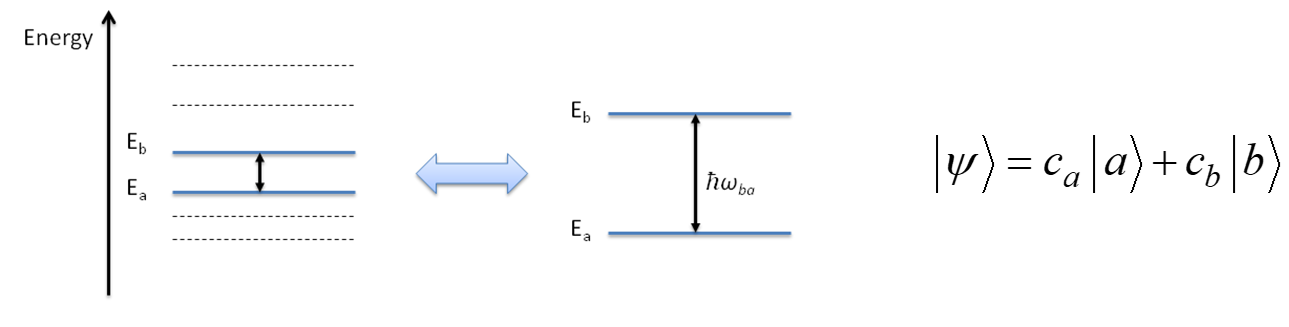

In its orthonormal energy eigenbasis,

$$
H=\begin{bmatrix}E_a&0\\0&E_b\end{bmatrix},
\qquad E_a,E_b\in\mathbb R.
$$

*The diagram reduces a larger spectrum to selected levels $E_a$ and $E_b$, whose separation defines the transition angular frequency.*


## Composite systems and the growth of state space

If systems $A$ and $B$ have Hilbert spaces $\mathcal H_A$ and $\mathcal H_B$, their joint state space is

$$
\mathcal H_{AB}=\mathcal H_A\otimes\mathcal H_B.
$$

For finite dimensions,

$$
\dim\mathcal H_{AB}=(\dim\mathcal H_A)(\dim\mathcal H_B).
$$

Two qubits therefore use a four-dimensional space with computational basis $|00\rangle,|01\rangle,|10\rangle,|11\rangle$. Product states have the form $|a\rangle\otimes|b\rangle$; a general vector in the joint space need not factor and may be entangled. Mixed states and reduced subsystem states require density operators, introduced later in the course.


In [27]:
zero_numeric = np.array([1, 0], dtype=complex)
one_numeric = np.array([0, 1], dtype=complex)
zero_one = np.kron(zero_numeric, one_numeric)
bell_phi_plus = (np.kron(zero_numeric, zero_numeric) + np.kron(one_numeric, one_numeric)) / np.sqrt(2)

print("|01>:", zero_one)
print("Bell-state probabilities:", np.abs(bell_phi_plus) ** 2)

|01>: [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
Bell-state probabilities: [0.5 0.  0.  0.5]


## Key takeaways

- Completeness and orthonormal expansions extend finite-dimensional vector geometry to wavefunctions and modes.
- The Born rule converts projection amplitudes into probabilities, and completeness makes those probabilities sum to one.
- The $X$, $Y$, and $Z$ qubit bases reveal different components of the same state.
- Composite systems use tensor-product spaces, so dimensions multiply and entangled states become possible.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. J. J. Sakurai and J. Napolitano, *Modern Quantum Mechanics*, 3rd edition, Chapters 1–2.
2. M. A. Nielsen and I. L. Chuang, [*Quantum Computation and Quantum Information*](https://www.cambridge.org/highereducation/books/quantum-computation-and-quantum-information/01E10196D0A682A6AEFFEA52D53BE9AE), Section 2.2.
3. J. Preskill, [Quantum Computation lecture notes](https://www.preskill.caltech.edu/ph229/), Chapter 2.
4. [SymPy Hilbert-space documentation](https://docs.sympy.org/latest/modules/physics/quantum/hilbert.html) and [Qubit documentation](https://docs.sympy.org/latest/modules/physics/quantum/qubit.html).
5. IBM Quantum Learning, [Single systems](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/single-systems/quantum-information) and [projective measurements](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/quantum-circuits/inner-products-and-projections).
6. MIT OpenCourseWare, [Quantum Physics I](https://ocw.mit.edu/courses/8-04-quantum-physics-i-spring-2016/).
